### Статистический анализ скидочной политики и прибыльности розничной сети «Соседушка»

**Бизнес-задача:** исследовать взаимосвязь скидок, размера покупательской корзины и валовой прибыли розничной сети.

**Цель:** выявить статистически обоснованные различия и закономерности, которые могут быть использованы для оценки скидочной политики.

**Данные:** синтетический датасет розничных продаж за 2024–2025 годы.

**Методы:** описательная статистика, визуализация распределений, доверительные интервалы, статистические критерии и оценка размеров эффекта.

In [44]:
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import scipy
import statsmodels
import matplotlib.pyplot as plt
import seaborn as sns

### Этап 1. Аудит исходных данных
**Цель:** понять структуру, гранулярность и качество исходных таблиц до статистических расчётов.

#### 1.1. Загружаем Excel и изучаем структуру

In [21]:
DATA_PATH = Path("../data/raw/simulative_retail_sales.xlsx")

assert DATA_PATH.exists(), f"Файл не найден: {DATA_PATH.resolve()}"

excel = pd.ExcelFile(DATA_PATH)

print("Листы Excel:")
for sheet in excel.sheet_names:
    print(f"- {sheet}")

Листы Excel:
- README
- fact_sales
- dim_products
- dim_stores
- dim_customers
- dim_suppliers


#### 1.2. Загрузка и первичный анализ структуры данных
На этом этапе проверяем состав исходных таблиц, количество наблюдений, названия столбцов и типы данных.

**Цель проверки** — определить структуру датасета, выявить потенциальные проблемы с типами данных и подготовить основу для дальнейшего анализа качества.

In [22]:
# Загружаем таблицы в словарь DataFrame
sheet_names = [
    'fact_sales',
    'dim_products',
    'dim_stores',
    'dim_customers',
    'dim_suppliers'
]

tables = {
    sheet: pd.read_excel(DATA_PATH, sheet_name=sheet)
    for sheet in sheet_names
}

# Формируем сводную информацию
structure_summary = pd.DataFrame([
    {
        "Таблица": name,
        "Строк": df.shape[0],
        "Столбцов": df.shape[1]
    }
    for name, df in tables.items()
])

display(structure_summary)

,Таблица,Строк,Столбцов
0,fact_sales,81238,10
1,dim_products,101,8
2,dim_stores,20,7
3,dim_customers,5000,7
4,dim_suppliers,20,4


#### 1.3. Проверяем названия столбцов и типы данных

In [23]:
for name, df in tables.items():
    print(f"\n{'=' * 60}")
    print(f"Таблица: {name}")
    print(f"{'=' * 60}")

    df.info()
    print("\nНазвания столбцов:")
    print(df.columns.tolist())


Таблица: fact_sales
<class 'pandas.DataFrame'>
RangeIndex: 81238 entries, 0 to 81237
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   id_чека          81238 non-null  int64         
 1   дата_время       81238 non-null  datetime64[us]
 2   id_магазина      81238 non-null  int64         
 3   id_товара        81238 non-null  int64         
 4   id_клиента       44744 non-null  float64       
 5   количество       81238 non-null  int64         
 6   цена_за_единицу  81238 non-null  float64       
 7   скидка_процент   81238 non-null  int64         
 8   сумма_строки     81238 non-null  float64       
 9   способ_оплаты    81238 non-null  str           
dtypes: datetime64[us](1), float64(3), int64(5), str(1)
memory usage: 6.2 MB

Названия столбцов:
['id_чека', 'дата_время', 'id_магазина', 'id_товара', 'id_клиента', 'количество', 'цена_за_единицу', 'скидка_процент', 'сумма_строки', 'способ_оплат

#### 1.4. Проверка гранулярности и уникальности ключей
Перед статистическим анализом необходимо определить единицу наблюдения и проверить уникальность идентификаторов в справочниках.

Дублирование ключей может привести к размножению строк при объединении таблиц и, как следствие, к искажению финансовых показателей.

In [24]:
# Проверяем уникальность ключей справочников
dimension_keys = {
    'dim_products': 'id_товара',
    'dim_stores': 'id_магазина',
    'dim_customers': 'id_клиента',
    'dim_suppliers': 'id_поставщика'
}

key_checks = []

for table_name, key in dimension_keys.items():
    df = tables[table_name]

    key_checks.append({
        "Таблица": table_name,
        "Ключ": key,
        "Строк": len(df),
        "Уникальных ключей": df[key].nunique(),
        "Дубликатов": df[key].duplicated().sum(),
        "Пропусков": df[key].isna().sum()
    })

    display(pd.DataFrame(key_checks))

,Таблица,Ключ,Строк,Уникальных ключей,Дубликатов,Пропусков
0,dim_products,id_товара,101,101,0,0


,Таблица,Ключ,Строк,Уникальных ключей,Дубликатов,Пропусков
0,dim_products,id_товара,101,101,0,0
1,dim_stores,id_магазина,20,20,0,0


,Таблица,Ключ,Строк,Уникальных ключей,Дубликатов,Пропусков
0,dim_products,id_товара,101,101,0,0
1,dim_stores,id_магазина,20,20,0,0
2,dim_customers,id_клиента,5000,5000,0,0


,Таблица,Ключ,Строк,Уникальных ключей,Дубликатов,Пропусков
0,dim_products,id_товара,101,101,0,0
1,dim_stores,id_магазина,20,20,0,0
2,dim_customers,id_клиента,5000,5000,0,0
3,dim_suppliers,id_поставщика,20,20,0,0


In [25]:
# Проверяем структуру чеков
sales = tables["fact_sales"]

check_summary = pd.DataFrame({
    "Показатель": [
        "Количество строк",
        "Количество уникальных чеков",
        "Среднее количество строк в чеке",
        "Максимальное количество строк в чеке",
        "Полностью дублирующиеся строки"
    ],
    "Значение": [
        len(sales),
        sales["id_чека"].nunique(),
        len(sales) / sales["id_чека"].nunique(),
        sales.groupby("id_чека").size().max(),
        sales.duplicated().sum()
    ]
})

display(check_summary)

,Показатель,Значение
0,Количество строк,81238.000000
1,Количество уникальных чеков,22790.000000
2,Среднее количество строк в чеке,3.564634
3,Максимальное количество строк в чеке,12.000000
4,Полностью дублирующиеся строки,0.000000


In [26]:
# Проверяем согласованность данных внутри чека
check_consistency = (
    sales.groupby("id_чека")
    .agg(
        stores=("id_магазина", "nunique"),
        timestamps=("дата_время", "nunique"),
        customers=("id_клиента", lambda x: x.nunique(dropna=False)),
        payments=("способ_оплаты", "nunique")
    )
)

consistency_result = pd.DataFrame({
    "Проверка": [
        "Чек связан с несколькими магазинами",
        "Чек содержит разные даты/время",
        "Чек связан с разными покупателями",
        "Чек содержит разные способы оплаты"
    ],
    "Количество проблемных чеков": [
        (check_consistency["stores"] > 1).sum(),
        (check_consistency["timestamps"] > 1).sum(),
        (check_consistency["customers"] > 1).sum(),
        (check_consistency["payments"] > 1).sum()
    ]
})

display(consistency_result)

,Проверка,Количество проблемных чеков
0,Чек связан с несколькими магазинами,0
1,Чек содержит разные даты/время,0
2,Чек связан с разными покупателями,0
3,Чек содержит разные способы оплаты,0


#### Вывод по проверке ключей и гранулярности

Проверена уникальность идентификаторов четырёх справочников. Дублирующиеся и отсутствующие значения первичных ключей не обнаружены.

Таблица продаж содержит 81 238 строк, объединённых в 22 790 уникальных чеков. Среднее количество товарных позиций на чек составляет 3,56, максимальное — 12.

Полных дубликатов строк не обнаружено. Все чеки согласованы по магазину, дате и времени, покупателю и способу оплаты.

**Единица наблюдения:** исходная строка соответствует товарной позиции продажи; для анализа среднего чека, размера корзины и валовой прибыли на покупку потребуется агрегация до уровня чека.

Следующий этап контроля качества — проверка соответствия внешних ключей справочникам, пропусков и допустимых диапазонов значений.

#### 1.5. Проверка ссылочной целостности

In [27]:
foreign_keys = [
    ("fact_sales", "id_товара", "dim_products", "id_товара"),
    ("fact_sales", "id_магазина", "dim_stores", "id_магазина"),
    ("fact_sales", "id_клиента", "dim_customers", "id_клиента"),
    ("dim_products", "id_поставщика", "dim_suppliers", "id_поставщика")
]

fk_results = []

for fact_name, fact_key, dim_name, dim_key in foreign_keys:
    fact = tables[fact_name]
    dim = tables[dim_name]

    # Для клиентов отсутствие ID допускается
    values = fact[fact_key].dropna()

    missing_mask = ~values.isin(dim[dim_key])

    fk_results.append({
        "Таблица": fact_name,
        "Внешний ключ": fact_key,
        "Справочник": dim_name,
        "Несопоставленных строк": missing_mask.sum(),
        "Уникальных отсутствующих ID": values[missing_mask].nunique()
    })

display(pd.DataFrame(fk_results))

,Таблица,Внешний ключ,Справочник,Несопоставленных строк,Уникальных отсутствующих ID
0,fact_sales,id_товара,dim_products,0,0
1,fact_sales,id_магазина,dim_stores,0,0
2,fact_sales,id_клиента,dim_customers,0,0
3,dim_products,id_поставщика,dim_suppliers,0,0


#### 1.6. Проверка пропусков

In [28]:
missing_results = []

for name, df in tables.items():
    for column in df.columns:
        missing_count = df[column].isna().sum()

        if missing_count > 0:
            missing_results.append({
                "Таблица": name,
                "Столбец": column,
                "Пропусков": missing_count,
                "Доля пропусков, %": round(
                    missing_count / len(df) * 100, 2
                )
            })

display(pd.DataFrame(missing_results))

,Таблица,Столбец,Пропусков,"Доля пропусков, %"
0,fact_sales,id_клиента,36494,44.92


#### 1.7. Проверка допустимых значений

In [29]:
sales = tables["fact_sales"]

value_checks = pd.DataFrame({
    "Проверка": [
        "Количество <= 0",
        "Цена за единицу <= 0",
        "Скидка < 0 или > 100%",
        "Сумма строки < 0",
        "Сумма строки = 0"
    ],
    "Количество строк": [
        (sales["количество"] <= 0).sum(),
        (sales["цена_за_единицу"] <= 0).sum(),
        (
            (sales["скидка_процент"] < 0) |
            (sales["скидка_процент"] > 100)
        ).sum(),
        (sales["сумма_строки"] < 0).sum(),
        (sales["сумма_строки"] == 0).sum()
    ]
})

display(value_checks)

print(
    "Уровни скидок:",
    sorted(sales["скидка_процент"].unique())
)

print(
    "Способы оплаты:",
    sales["способ_оплаты"].unique()
)

,Проверка,Количество строк
0,Количество <= 0,0
1,Цена за единицу <= 0,0
2,Скидка < 0 или > 100%,0
3,Сумма строки < 0,0
4,Сумма строки = 0,0


Уровни скидок: [np.int64(0), np.int64(5), np.int64(10), np.int64(15)]
Способы оплаты: <StringArray>
['карта', 'СБП', 'наличные']
Length: 3, dtype: str


#### Вывод по проверке ссылочной целостности, пропусков и допустимых значений

Проверка ссылочной целостности не выявила несоответствий между таблицей продаж и справочниками товаров, магазинов, покупателей и поставщиков.

Пропущенные значения обнаружены только в поле `id_клиента`: 36 494 строки (44,92%). Предположительно, пропуски связаны с покупками без идентификации клиента в программе лояльности. На текущем этапе строки сохранены.

В количественных полях не выявлено нулевых или отрицательных значений количества, цены и суммы продажи. Скидки находятся в допустимом диапазоне и принимают значения 0%, 5%, 10% и 15%.

Проверенные структурные и диапазонные характеристики не содержат нарушений. Для завершения аудита необходимо проверить корректность расчёта сумм продаж и бизнес-правила применения скидок.

#### 1.8. Проверка финансовых расчётов

In [30]:
# Рассчитываем ожидаемую сумму продажи
expected_amount = (
    sales["количество"]
    * sales["цена_за_единицу"]
    * (1 - sales["скидка_процент"] / 100)
)

# Рассчитываем абсолютное расхождение
amount_diff = (sales["сумма_строки"] - expected_amount).abs()

# Допуск 1 копейка на округление
tolerance = 0.01

financial_checks = pd.DataFrame({
    "Показатель": [
        "Количество проверенных строк",
        "Строк с расхождением более 1 копейки",
        "Максимальное расхождение, руб.",
        "Среднее расхождение, руб."
    ],
    "Значение": [
        len(sales),
        (amount_diff > tolerance).sum(),
        amount_diff.max(),
        amount_diff.mean()
    ]
})

display(financial_checks)

,Показатель,Значение
0,Количество проверенных строк,81238.000000
1,Строк с расхождением более 1 копейки,0.000000
2,"Максимальное расхождение, руб.",0.005000
3,"Среднее расхождение, руб.",0.000491


#### 1.9. Проверка бизнес-правил скидок

In [31]:
# Признак наличия идентификатора клиента
sales["has_customer_id"] = sales["id_клиента"].notna()

# Признак применения скидки
sales["has_discount"] = sales["скидка_процент"] > 0

# Таблица распределения товарных позиций
discount_customer_check = pd.crosstab(
    sales["has_customer_id"],
    sales["has_discount"],
    margins=True
)

display(discount_customer_check)

has_discount,False,True,All
has_customer_id,,,
False,36494,0,36494
True,28911,15833,44744
All,65405,15833,81238


#### Вывод по финансовым расчётам и применению скидок

Проверка 81 238 строк продаж не выявила расхождений между исходной суммой продажи и расчётной величиной более 0,01 ₽. Максимальное абсолютное расхождение составило 0,005 ₽, что согласуется с округлением денежных значений.

Анализ применения скидок показал, что все 15 833 товарные позиции со скидкой связаны с идентифицированными покупателями. Среди позиций с заполненным `id_клиента` доля скидочных продаж составляет 35,39%.

Полученная закономерность согласуется с предполагаемым правилом предоставления скидок участникам программы лояльности.

**Методологическое следствие:** при проверке различий между покупками со скидкой и без скидки необходимо учитывать наличие идентификатора клиента. Основное сравнение среднего чека будет проводиться среди идентифицированных покупателей.

Исходная сумма продажи признана пригодной для дальнейшего анализа выручки.

#### 1.10. Проверка временного охвата данных

In [32]:
# Границы исследуемого периода
start_date = pd.Timestamp("2024-01-01")
end_date = pd.Timestamp("2026-01-01")

date_checks = pd.DataFrame({
    "Показатель": [
        "Минимальная дата продажи",
        "Максимальная дата продажи",
        "Продаж вне периода 2024–2025",
        "Количество месяцев с продажами",
        "Продаж раньше открытия магазина"
    ],
    "Значение": [
        sales["дата_время"].min(),
        sales["дата_время"].max(),
        (
            (sales["дата_время"] < start_date) |
            (sales["дата_время"] >= end_date)
        ).sum(),
        sales["дата_время"].dt.to_period("M").nunique(),
        (
            sales.merge(
                tables["dim_stores"][["id_магазина", "дата_открытия"]],
                on="id_магазина",
                how="left",
                validate="many_to_one"
            )
            .eval("дата_время < дата_открытия")
            .sum()
        )
    ]
})

display(date_checks)

,Показатель,Значение
0,Минимальная дата продажи,2024-01-01 09:42:00
1,Максимальная дата продажи,2025-12-31 22:40:00
2,Продаж вне периода 2024–2025,0
3,Количество месяцев с продажами,24
4,Продаж раньше открытия магазина,0


### Итоги аудита качества данных

Проведён аудит исходного набора данных розничной сети «Соседушка», включающего 81 238 товарных позиций, 22 790 чеков и справочники товаров, магазинов, покупателей и поставщиков.

**Результаты проверки:**

- Первичные ключи справочников уникальны, пропуски и дубликаты отсутствуют.
- Согласованность чеков по магазину, дате, покупателю и способу оплаты подтверждена.
- Нарушений ссылочной целостности не обнаружено.
- Некорректных значений количества, цены, суммы продажи и процента скидки не выявлено.
- Расхождения между исходными и расчётными суммами продаж не превышают 0,005 ₽.
- Продажи охватывают 24 месяца — с января 2024 по декабрь 2025 года. Продаж до открытия магазинов не обнаружено.
- Пропуски присутствуют только в поле `id_клиента` (44,92% строк). Все позиции со скидкой связаны с идентифицированными покупателями.

**Заключение:** критических нарушений качества данных по выполненным проверкам не выявлено. Исходные наблюдения сохраняются без исключений.

Для дальнейшего анализа будут сформированы две аналитические выборки:

1. На уровне товарной позиции — для изучения скидок, категорий и маржинальности.
2. На уровне чека — для анализа размера покупательской корзины, среднего чека и валовой прибыли на покупку.

При интерпретации результатов необходимо учитывать синтетическое происхождение данных и ограничения расчётной себестоимости.

### Этап 2. Подготовка аналитических данных
**Цель этапа:** преобразовать исходные данные продаж в аналитические таблицы, пригодные для расчёта статистических характеристик и проверки гипотез

#### 2.1. Объединение исходных таблиц
Для последующего статистического анализа необходимо дополнить исходные продажи информацией о категориях товаров, закупочных ценах и форматах магазинов.

Объединение выполняется по идентификаторам товара и магазина с использованием левого соединения (left join).

Для контроля корректности применяется ограничение many_to_one: каждой товарной позиции должна соответствовать не более одной записи в каждом справочнике.

После объединения проверяем количество строк, отсутствие дубликатов новых столбцов и полноту присоединённых характеристик.

In [33]:
# Выбираем необходимые поля справочников
product_columns = [
    "id_товара",
    "категория",
    "подкатегория",
    "цена_закупки_руб"
]

store_columns = [
    "id_магазина",
    "формат_магазина",
    "город",
    "регион"
]

# Формируем отдельную аналитическую таблицу
sales_items = (
    sales.copy()
    .merge(
        tables["dim_products"][product_columns],
        on="id_товара",
        how="left",
        validate="many_to_one"
    )
    .merge(
        tables["dim_stores"][store_columns],
        on="id_магазина",
        how="left",
        validate="many_to_one"
    )
)

print("Строк в исходной таблице:", len(sales))
print("Строк после объединения:", len(sales_items))
print("Количество столбцов:", sales_items.shape[1])

display(sales_items.head())

Строк в исходной таблице: 81238
Строк после объединения: 81238
Количество столбцов: 18


,id_чека,дата_время,id_магазина,id_товара,id_клиента,количество,цена_за_единицу,скидка_процент,сумма_строки,способ_оплаты,has_customer_id,has_discount,категория,подкатегория,цена_закупки_руб,формат_магазина,город,регион
0,1000001,2024-01-01 20:32:00,1,89,864.0,3,326.18,10,880.69,карта,True,True,Снеки,Орехи,236.23,гипермаркет,Москва,Москва и МО
1,1000001,2024-01-01 20:32:00,1,99,864.0,1,187.24,0,187.24,карта,True,False,Детское питание,Каши,132.04,гипермаркет,Москва,Москва и МО
2,1000001,2024-01-01 20:32:00,1,49,864.0,1,95.26,0,95.26,карта,True,False,Сладости,Печенье,67.56,гипермаркет,Москва,Москва и МО
3,1000001,2024-01-01 20:32:00,1,48,864.0,1,273.40,0,273.40,карта,True,False,Сладости,Конфеты,178.58,гипермаркет,Москва,Москва и МО
4,1000001,2024-01-01 20:32:00,1,21,864.0,1,127.58,0,127.58,карта,True,False,Овощи и фрукты,Фрукты,97.33,гипермаркет,Москва,Москва и МО


In [34]:
# Контроль количества строк
assert len(sales_items) == len(sales), \
    "Количество строк изменилось после объединения"

# Контроль уникальности названий столбцов
assert sales_items.columns.is_unique, \
    "После объединения появились повторяющиеся названия столбцов"

# Проверка заполненности присоединённых полей
joined_columns = [
    "категория",
    "подкатегория",
    "цена_закупки_руб",
    "формат_магазина",
    "город",
    "регион"
]

join_checks = pd.DataFrame({
    "Поле": joined_columns,
    "Пропусков после объединения": [
        sales_items[col].isna().sum()
        for col in joined_columns
    ]
})

display(join_checks)

,Поле,Пропусков после объединения
0,категория,0
1,подкатегория,0
2,цена_закупки_руб,0
3,формат_магазина,0
4,город,0
5,регион,0


#### Вывод по объединению таблиц
Объединение фактов продаж со справочниками товаров и магазинов выполнено без потери или размножения строк. Все присоединённые характеристики заполнены. Аналитическая таблица содержит 81 238 товарных позиций и готова к расчёту финансовых показателей.

#### 2.2. Расчёт финансовых показателей

Какие показатели рассчитываем

|Показатель|	Формула|	Бизнес-смысл|
|---|---|---|
|Выручка до скидки|	Количество × цена|	Стоимость проданных товаров без учёта скидок|
|Выручка после скидки|	сумма_строки|	Фактическая выручка|
|Сумма скидки|	Выручка до − выручка после|	Сколько рублей составил дисконт|
|Себестоимость|	Количество × закупочная цена|	Оценочная стоимость проданных товаров|
|Валовая прибыль|	Выручка после − себестоимость|	Финансовый результат до операционных расходов|
|Валовая маржа|	Валовая прибыль / выручка после × 100%|	Какая доля выручки остаётся после покрытия закупочной стоимости|

In [35]:
# Выручка до скидки
sales_items["revenue_before_discount"] = (
    sales_items["количество"]
    * sales_items["цена_за_единицу"]
)

# Выручка после скидки
sales_items["revenue"] = sales_items["сумма_строки"]

# Денежная величина скидки
sales_items["discount_amount"] = (
    sales_items["revenue_before_discount"]
    - sales_items["revenue"]
)

# Оценочная себестоимость
sales_items["purchase_cost"] = (
    sales_items["количество"]
    * sales_items["цена_закупки_руб"]
)

# Валовая прибыль
sales_items["gross_profit"] = (
    sales_items["revenue"]
    - sales_items["purchase_cost"]
)

# Валовая маржа, %
sales_items["gross_margin_pct"] = (
    sales_items["gross_profit"]
    / sales_items["revenue"]
    * 100
)

In [36]:
financial_columns = [
    "количество",
    "цена_за_единицу",
    "скидка_процент",
    "revenue_before_discount",
    "discount_amount",
    "revenue",
    "purchase_cost",
    "gross_profit",
    "gross_margin_pct"
]

display(
    sales_items[financial_columns].head(10).round(2)
)

,количество,цена_за_единицу,скидка_процент,revenue_before_discount,discount_amount,revenue,purchase_cost,gross_profit,gross_margin_pct
0,3,326.18,10,978.54,97.85,880.69,708.69,172.00,19.53
1,1,187.24,0,187.24,0.00,187.24,132.04,55.20,29.48
2,1,95.26,0,95.26,0.00,95.26,67.56,27.70,29.08
3,1,273.40,0,273.40,0.00,273.40,178.58,94.82,34.68
4,1,127.58,0,127.58,0.00,127.58,97.33,30.25,23.71
5,2,215.60,0,431.20,0.00,431.20,261.76,169.44,39.29
6,1,82.48,0,82.48,0.00,82.48,50.98,31.50,38.19
7,1,639.60,0,639.60,0.00,639.60,446.61,192.99,30.17
8,1,124.77,0,124.77,0.00,124.77,93.65,31.12,24.94
9,1,507.26,0,507.26,0.00,507.26,391.10,116.16,22.90


In [37]:
financial_validation = pd.DataFrame({
    "Проверка": [
        "Выручка до скидки меньше выручки после",
        "Отрицательная сумма скидки",
        "Отрицательная себестоимость",
        "Отрицательная валовая прибыль",
        "Валовая маржа выше 100%",
        "Пропуски в расчётных показателях"
    ],
    "Количество строк": [
        (
            sales_items["revenue_before_discount"]
            < sales_items["revenue"] - 0.01
        ).sum(),
        (sales_items["discount_amount"] < -0.01).sum(),
        (sales_items["purchase_cost"] < 0).sum(),
        (sales_items["gross_profit"] < 0).sum(),
        (sales_items["gross_margin_pct"] > 100).sum(),
        sales_items[
            [
                "revenue_before_discount",
                "discount_amount",
                "revenue",
                "purchase_cost",
                "gross_profit",
                "gross_margin_pct"
            ]
        ].isna().sum().sum()
    ]
})

display(financial_validation)

,Проверка,Количество строк
0,Выручка до скидки меньше выручки после,0
1,Отрицательная сумма скидки,0
2,Отрицательная себестоимость,0
3,Отрицательная валовая прибыль,7
4,Валовая маржа выше 100%,0
5,Пропуски в расчётных показателях,0


#### Промежуточный вывод по финансовым показателям

На основе исходных продаж и закупочных цен рассчитаны выручка до и после скидки, денежная величина скидки, оценочная себестоимость, валовая прибыль и валовая маржа.

Проверка расчётных показателей не выявила отрицательной себестоимости, недопустимых значений валовой маржи или пропусков.

В семи товарных позициях (около 0,009% наблюдений) выявлена отрицательная валовая прибыль. Эти случаи требуют дополнительного анализа по категориям, размерам скидок и сумме финансовых отклонений.

Поскольку исторические закупочные цены отсутствуют, показатели себестоимости и валовой прибыли рассматриваются как оценочные.

In [39]:
# Дополнительная проверка семи позиций
negative_profit = sales_items.loc[
    sales_items["gross_profit"] < 0,
    [
        "id_чека",
        "id_товара",
        "категория",
        "подкатегория",
        "скидка_процент",
        "revenue",
        "purchase_cost",
        "gross_profit",
        "gross_margin_pct"
    ]
].copy()

display(
    negative_profit
    .sort_values("gross_profit")
    .round(2)
)

print(
    "Суммарная отрицательная валовая прибыль:",
    round(negative_profit["gross_profit"].sum(), 2),
    "руб."
)

,id_чека,id_товара,категория,подкатегория,скидка_процент,revenue,purchase_cost,gross_profit,gross_margin_pct
19257,1005468,62,Бакалея,Сахар и соль,15,71.11,72.2,-1.09,-1.53
27592,1007818,62,Бакалея,Сахар и соль,15,71.33,72.2,-0.87,-1.22
36514,1010374,62,Бакалея,Сахар и соль,15,71.50,72.2,-0.70,-0.98
61302,1017289,62,Бакалея,Сахар и соль,15,71.83,72.2,-0.37,-0.52
55808,1015762,62,Бакалея,Сахар и соль,15,71.88,72.2,-0.32,-0.45
20918,1005936,62,Бакалея,Сахар и соль,15,144.31,144.4,-0.09,-0.06
79457,1022311,62,Бакалея,Сахар и соль,15,72.17,72.2,-0.03,-0.04


Суммарная отрицательная валовая прибыль: -3.47 руб.


#### Анализ продаж с отрицательной валовой прибылью

Выявлено семь товарных позиций с отрицательной оценочной валовой прибылью. Все случаи относятся к одному товару (`id_товара = 62`, категория «Бакалея», подкатегория «Сахар и соль») и сопровождаются максимальной скидкой 15%.

Суммарная отрицательная валовая прибыль составила 3,47 ₽, минимальная маржа — −1,53%.

Масштаб отклонений не указывает на существенные финансовые потери для сети. Однако результаты демонстрируют потенциальный риск применения максимальных скидок к товарам с низкой исходной маржинальностью.

Оценка эффективности таких продаж требует анализа прибыльности всего чека, а не отдельной товарной позиции.

#### 2.3. Формирование аналитической таблицы на уровне чека
Для анализа покупательского поведения и финансового результата покупки исходные товарные позиции агрегируются до уровня чека.

В рамках агрегации рассчитываются:

|Показатель|	Как рассчитывае
|---|---|
|revenue|	Сумма выручки всех позиций|
|revenue_before_discount|	Сумма до скидок|
|discount_amount|	Общая сумма скидок|
|purchase_cost|	Суммарная оценочная себестоимость|
|gross_profit|	Валовая прибыль всего чека|
|gross_margin_pct|	Валовая прибыль / выручка × 100|
|items_count|	Количество товарных позиций|
|units_count|	Количество купленных единиц|
|has_discount|	Есть ли хотя бы одна позиция со скидкой|
|effective_discount_pct|	Фактическая доля скидки в первоначальной стоимости чека|

Для классификации покупок используется признак наличия хотя бы одной скидочной позиции. Эффективный процент скидки определяется как:

$
D_{\text{эфф}} = \frac{\text{Сумма скидок}}{\text{Выручка до скидок}}\times100\%
$

Результирующая таблица должна содержать одну строку на каждый уникальный чек.

In [40]:
# Агрегация товарных позиций до уровня чека
sales_checks = (
    sales_items
    .groupby("id_чека", as_index=False)
    .agg(
        date=("дата_время", "first"),
        store_id=("id_магазина", "first"),
        customer_id=("id_клиента", "first"),
        store_format=("формат_магазина", "first"),
        payment_type=("способ_оплаты", "first"),
        revenue=("revenue", "sum"),
        revenue_before_discount=("revenue_before_discount", "sum"),
        discount_amount=("discount_amount", "sum"),
        purchase_cost=("purchase_cost", "sum"),
        gross_profit=("gross_profit", "sum"),
        items_count=("id_товара", "size"),
        units_count=("количество", "sum"),
        has_discount=("has_discount", "any")
    )
)

# Признак идентифицированного покупателя
sales_checks["has_customer_id"] = (
    sales_checks["customer_id"].notna()
)

# Эффективный процент скидки
sales_checks["effective_discount_pct"] = (
    sales_checks["discount_amount"]
    / sales_checks["revenue_before_discount"]
    * 100
)

# Валовая маржа всего чека
sales_checks["gross_margin_pct"] = (
    sales_checks["gross_profit"]
    / sales_checks["revenue"]
    * 100
)

print("Количество чеков:", len(sales_checks))
print("Количество столбцов:", sales_checks.shape[1])

display(sales_checks.head())

Количество чеков: 22790
Количество столбцов: 17


,id_чека,date,store_id,customer_id,store_format,payment_type,revenue,revenue_before_discount,discount_amount,purchase_cost,gross_profit,items_count,units_count,has_discount,has_customer_id,effective_discount_pct,gross_margin_pct
0,1000001,2024-01-01 20:32:00,1,864.0,гипермаркет,карта,1564.17,1662.02,9.785000e+01,1184.20,379.97,5,7,True,True,5.887414e+00,24.292117
1,1000002,2024-01-01 15:22:00,2,NaN,супермаркет,СБП,1153.28,1153.28,0.000000e+00,759.35,393.93,3,4,False,False,0.000000e+00,34.157360
2,1000003,2024-01-01 12:57:00,2,NaN,супермаркет,карта,632.03,632.03,0.000000e+00,484.75,147.28,2,2,False,False,0.000000e+00,23.302691
3,1000004,2024-01-01 18:22:00,3,1568.0,супермаркет,карта,967.26,996.19,2.893000e+01,696.41,270.85,5,7,True,True,2.904064e+00,28.001778
4,1000005,2024-01-01 16:24:00,3,NaN,супермаркет,карта,783.90,783.90,1.136868e-13,580.95,202.95,1,3,False,False,1.450272e-14,25.889782


In [41]:
# Сверяем результаты до и после агрегации

metrics = [
    "revenue",
    "revenue_before_discount",
    "discount_amount",
    "purchase_cost",
    "gross_profit"
]

aggregation_checks = pd.DataFrame([
    {
        "Показатель": metric,
        "Сумма товарных позиций": sales_items[metric].sum(),
        "Сумма по чекам": sales_checks[metric].sum(),
        "Расхождение": (
            sales_items[metric].sum()
            - sales_checks[metric].sum()
        )
    }
    for metric in metrics
])

display(aggregation_checks.round(2))

print(
    "Количество чеков совпадает:",
    len(sales_checks) == sales_items["id_чека"].nunique()
)

print(
    "Уникальность id_чека:",
    sales_checks["id_чека"].is_unique
)

print(
    "Количество товарных позиций совпадает:",
    sales_checks["items_count"].sum() == len(sales_items)
)

print(
    "Количество проданных единиц совпадает:",
    sales_checks["units_count"].sum()
    == sales_items["количество"].sum()
)

,Показатель,Сумма товарных позиций,Сумма по чекам,Расхождение
0,revenue,21889600.33,21889600.33,0.0
1,revenue_before_discount,22323175.79,22323175.79,0.0
2,discount_amount,433575.46,433575.46,0.0
3,purchase_cost,16129800.34,16129800.34,0.0
4,gross_profit,5759799.99,5759799.99,0.0


Количество чеков совпадает: True
Уникальность id_чека: True
Количество товарных позиций совпадает: True
Количество проданных единиц совпадает: True


### Итоги подготовки аналитических данных

На основе исходной таблицы продаж сформированы две аналитические выборки:

- `sales_items` — 81 238 товарных позиций с характеристиками товаров, магазинов и расчётными финансовыми показателями.
- `sales_checks` — 22 790 уникальных чеков, содержащих агрегированные показатели выручки, скидок, оценочной себестоимости, валовой прибыли и покупательской корзины.

Контрольная сверка подтвердила совпадение финансовых показателей до и после агрегации. Расхождений при отображении сумм с точностью до копеек не обнаружено.

Общая выручка после скидок составила 21,89 млн ₽, оценочная валовая прибыль — 5,76 млн ₽. Агрегированная валовая маржа сети составила 26,31%, доля предоставленных скидок в стоимости товаров до скидок — 1,94%.

Подготовленные выборки позволяют проводить статистический анализ на двух уровнях детализации без повторного расчёта исходных финансовых показателей.

Показатели прибыли и маржинальности являются оценочными, поскольку используются закупочные цены из справочника товаров без истории их изменения.

### Этап 3. Описательный статистический анализ

#### 3.1. Анализ центральной тенденции и разброса суммы чека

На первом этапе описательного анализа исследуем распределение суммы покупки на уровне чека.

Среднее и медиана позволяют оценить характерный размер покупки, а стандартное отклонение, квартили и межквартильный размах — определить степень неоднородности чеков.

Дополнительно рассчитывается коэффициент вариации для оценки относительного разброса.

Полученные характеристики необходимы для последующего сравнения скидочных покупок и покупок без скидок, и обоснованного выбора статистических методов.

In [42]:
# Суммы чеков
check_revenue = sales_checks["revenue"]

# Основные статистические характеристики
mean_revenue = check_revenue.mean()
median_revenue = check_revenue.median()
std_revenue = check_revenue.std()

q1 = check_revenue.quantile(0.25)
q3 = check_revenue.quantile(0.75)
iqr = q3 - q1

min_revenue = check_revenue.min()
max_revenue = check_revenue.max()

# Коэффициент вариации
cv_revenue = std_revenue / mean_revenue * 100

revenue_stats = pd.DataFrame({
    "Характеристика": [
        "Количество чеков",
        "Среднее, ₽",
        "Медиана, ₽",
        "Стандартное отклонение, ₽",
        "Минимум, ₽",
        "Первый квартиль (Q1), ₽",
        "Третий квартиль (Q3), ₽",
        "Межквартильный размах (IQR), ₽",
        "Максимум, ₽",
        "Коэффициент вариации, %"
    ],
    "Значение": [
        check_revenue.count(),
        mean_revenue,
        median_revenue,
        std_revenue,
        min_revenue,
        q1,
        q3,
        iqr,
        max_revenue,
        cv_revenue
    ]
})

display(revenue_stats.round(2))

,Характеристика,Значение
0,Количество чеков,22790.00
1,"Среднее, ₽",960.49
2,"Медиана, ₽",731.76
3,"Стандартное отклонение, ₽",829.12
4,"Минимум, ₽",33.48
5,"Первый квартиль (Q1), ₽",329.96
6,"Третий квартиль (Q3), ₽",1351.54
7,"Межквартильный размах (IQR), ₽",1021.58
8,"Максимум, ₽",6947.38
9,"Коэффициент вариации, %",86.32


In [43]:
skew_revenue = check_revenue.skew()

print(f"Асимметрия распределения: {skew_revenue:.3f}")

Асимметрия распределения: 1.501


#### Вывод по описательной статистике суммы чека

Проанализированы 22 790 чеков розничной сети.

Средний чек составил 960,49 ₽, медианный — 731,76 ₽. Превышение среднего над медианой на 31,3% свидетельствует о влиянии крупных покупок на среднее значение.

Стандартное отклонение составило 829,12 ₽, коэффициент вариации — 86,32%. Это указывает на значительную неоднородность покупок по сумме.

Центральные 50% чеков находятся в диапазоне от 329,96 до 1 351,54 ₽. Максимальная сумма покупки составляет 6 947,38 ₽.

Коэффициент асимметрии равен 1,501, что свидетельствует о выраженной правосторонней асимметрии распределения.

**Практический вывод:** для описания покупательского поведения следует использовать среднее и медиану совместно. При последующем сравнении скидочных и нескиточных чеков необходимо учитывать асимметрию и возможное влияние крупных покупок на результаты статистических проверок.

#### 3.2. Визуализация распределения чеков и анализ выбросов

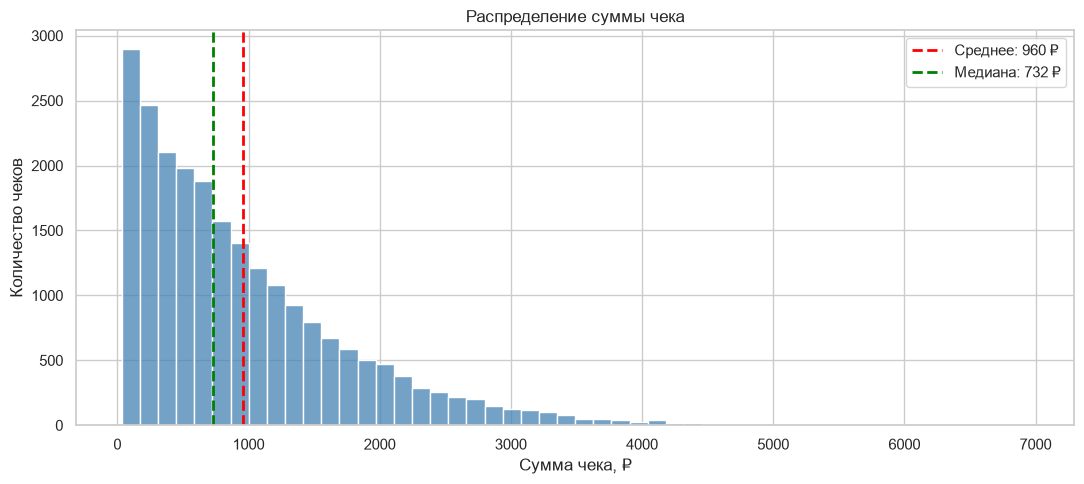

In [45]:
# Анализ распределения чеков и потенциальных выбросов
sns.set_theme(style="whitegrid")

fig, ax = plt.subplots(figsize=(11, 5))

sns.histplot(
    data=sales_checks,
    x="revenue",
    bins=50,
    color="steelblue",
    ax=ax
)

ax.axvline(
    mean_revenue,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Среднее: {mean_revenue:,.0f} ₽"
)

ax.axvline(
    median_revenue,
    color="green",
    linestyle="--",
    linewidth=2,
    label=f"Медиана: {median_revenue:,.0f} ₽"
)

ax.set(
    title="Распределение суммы чека",
    xlabel="Сумма чека, ₽",
    ylabel="Количество чеков"
)

ax.legend()
plt.tight_layout()
plt.show()

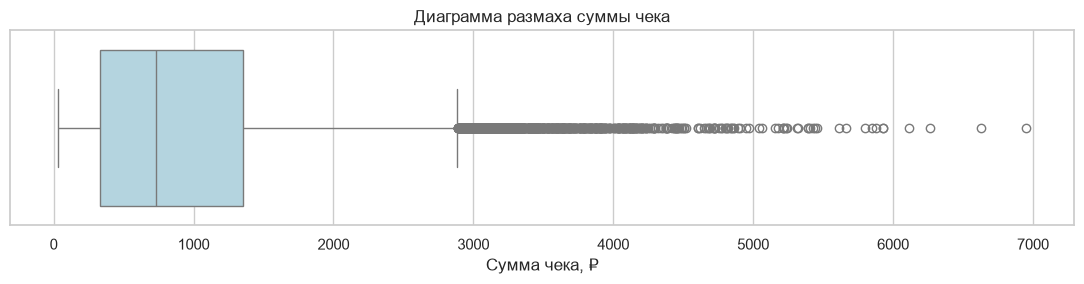

In [46]:
# Boxplot — диаграмма размаха
fig, ax = plt.subplots(figsize=(11, 3))

sns.boxplot(
    data=sales_checks,
    x="revenue",
    color="lightblue",
    ax=ax
)

ax.set(
    title="Диаграмма размаха суммы чека",
    xlabel="Сумма чека, ₽"
)

plt.tight_layout()
plt.show()

In [47]:
# Рассчитаем количество потенциальных выбросов
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

outliers = sales_checks[
    (sales_checks["revenue"] < lower_bound) |
    (sales_checks["revenue"] > upper_bound)
]

outlier_summary = pd.DataFrame({
    "Показатель": [
        "Нижняя граница, ₽",
        "Верхняя граница, ₽",
        "Количество потенциальных выбросов",
        "Доля потенциальных выбросов, %",
        "Выручка потенциальных выбросов, ₽",
        "Доля в общей выручке, %"
    ],
    "Значение": [
        lower_bound,
        upper_bound,
        len(outliers),
        len(outliers) / len(sales_checks) * 100,
        outliers["revenue"].sum(),
        outliers["revenue"].sum() / sales_checks["revenue"].sum() * 100
    ]
})

display(outlier_summary.round(2))

,Показатель,Значение
0,"Нижняя граница, ₽",-1202.41
1,"Верхняя граница, ₽",2883.92
2,Количество потенциальных выбросов,787.00
3,"Доля потенциальных выбросов, %",3.45
4,"Выручка потенциальных выбросов, ₽",2789053.91
5,"Доля в общей выручке, %",12.74


### 3.3. Анализ суммы чека по форматам магазинов

Первичный анализ выявил выраженную правостороннюю асимметрию распределения суммы чека и значительную вариативность покупок.

Одно из возможных объяснений — неоднородность форматов магазинов, которые могут обслуживать разные покупательские потребности.

Для проверки этого предположения анализируем распределение суммы чека отдельно по каждому формату: рассчитываем среднее, медиану, стандартное отклонение, квартили, коэффициент вариации и асимметрию.

Это позволит определить, насколько различается покупательское поведение между форматами и целесообразно ли учитывать их при дальнейшей проверке гипотез о скидках.

In [48]:
format_stats = (
    sales_checks
    .groupby("store_format")["revenue"]
    .agg(
        checks_count="count",
        mean="mean",
        median="median",
        std="std",
        q1=lambda x: x.quantile(0.25),
        q3=lambda x: x.quantile(0.75),
        min="min",
        max="max",
        skew="skew"
    )
)

format_stats["iqr"] = (
    format_stats["q3"] - format_stats["q1"]
)

format_stats["cv_pct"] = (
    format_stats["std"] / format_stats["mean"] * 100
)

display(
    format_stats
    .sort_values("mean")
    .round(2)
)

,checks_count,mean,median,std,q1,q3,min,max,skew,iqr,cv_pct
store_format,,,,,,,,,,,
у дома,7686,484.63,352.88,436.58,162.43,663.32,33.48,3430.30,1.79,500.89,90.08
супермаркет,10008,966.47,836.58,666.41,462.76,1320.92,34.11,6115.62,1.12,858.16,68.95
гипермаркет,5096,1666.45,1515.94,1036.79,892.34,2283.79,39.09,6947.38,0.79,1391.45,62.22


#### Вывод по сравнению форматов магазинов

Анализ выявил существенные описательные различия в размерах покупок между форматами торговой сети.

Средний чек составляет 484,63 ₽ в магазинах у дома, 966,47 ₽ в супермаркетах и 1 666,45 ₽ в гипермаркетах. Средний чек гипермаркета в 3,44 раза превышает показатель магазина у дома.

Относительный разброс, измеренный коэффициентом вариации, составляет 90,08%, 68,95% и 62,22% соответственно. Таким образом, при увеличении масштаба торгового формата наблюдается снижение относительной вариативности чеков.

Во всех форматах сохраняется правосторонняя асимметрия распределения, наиболее выраженная в магазинах у дома (1,79).

**Методологический вывод:** формат магазина необходимо учитывать при анализе связи скидок с размером покупательской корзины. Сравнение только общесетевых показателей может скрывать различия между группами и приводить к некорректной бизнес-интерпретации.

Статистическая значимость различий будет оценена на этапе проверки гипотез.

#### 3.4. Анализ потенциальных выбросов с учётом формата магазина

In [49]:
# Рассчитываем индивидуальные границы выбросов
format_bounds = format_stats[["q1", "q3", "iqr"]].copy()

format_bounds["lower_bound"] = (
    format_bounds["q1"] - 1.5 * format_bounds["iqr"]
)

format_bounds["upper_bound"] = (
    format_bounds["q3"] + 1.5 * format_bounds["iqr"]
)

# Добавляем границы к каждому чеку
checks_with_bounds = sales_checks.merge(
    format_bounds[["lower_bound", "upper_bound"]],
    left_on="store_format",
    right_index=True,
    how="left",
    validate="many_to_one"
)

# Определяем потенциальные выбросы внутри формата
checks_with_bounds["is_outlier"] = (
    (checks_with_bounds["revenue"] < checks_with_bounds["lower_bound"]) |
    (checks_with_bounds["revenue"] > checks_with_bounds["upper_bound"])
)

# Сводная таблица
format_outliers = (
    checks_with_bounds
    .groupby("store_format")
    .agg(
        checks_count=("id_чека", "size"),
        outliers_count=("is_outlier", "sum"),
        upper_bound=("upper_bound", "first")
    )
)

format_outliers["outliers_pct"] = (
    format_outliers["outliers_count"]
    / format_outliers["checks_count"]
    * 100
)

display(format_outliers.round(2))

,checks_count,outliers_count,upper_bound,outliers_pct
store_format,,,,
гипермаркет,5096,71,4370.96,1.39
супермаркет,10008,237,2608.16,2.37
у дома,7686,374,1414.66,4.87


#### Вывод по анализу потенциальных выбросов

Применение правила межквартильного размаха отдельно для каждого формата выявило различия в распределении крупных покупок.

В гипермаркетах доля потенциальных выбросов составила 1,39% при верхней границе 4 370,96 ₽, в супермаркетах — 2,37% при границе 2 608,16 ₽, в магазинах у дома — 4,87% при границе 1 414,66 ₽.

Всего по индивидуальным границам форматов выявлено 682 потенциальных выброса против 787 при расчёте единого общесетевого порога.

Результаты подтверждают необходимость учитывать формат магазина при описании распределения суммы чека. Единая граница может классифицировать как нетипичные покупки, которые характерны для гипермаркетов, и не выявлять относительно крупные покупки в магазинах меньшего формата.

Потенциальные выбросы сохраняются в анализе, поскольку их наличие само по себе не свидетельствует об ошибках данных.

#### 3.5. Анализ размера покупательской корзины

Для объяснения различий в суммах чеков между форматами магазинов исследуем количество товарных позиций и общее количество приобретённых единиц товара.

Анализ позволит установить, сопровождается ли увеличение среднего чека ростом количества приобретаемых товаров.

Для каждого формата рассчитываем среднее, медиану и стандартное отклонение количества товарных позиций и единиц товара на чек.

Результаты будут использованы при интерпретации различий в размере покупок и последующей проверке гипотез о скидках.

In [50]:
basket_stats = (
    sales_checks
    .groupby("store_format")
    .agg(
        checks_count=("id_чека", "size"),
        avg_items=("items_count", "mean"),
        median_items=("items_count", "median"),
        std_items=("items_count", "std"),
        avg_units=("units_count", "mean"),
        median_units=("units_count", "median"),
        std_units=("units_count", "std"),
        avg_revenue=("revenue", "mean")
    )
)

display(basket_stats.round(2))

,checks_count,avg_items,median_items,std_items,avg_units,median_units,std_units,avg_revenue
store_format,,,,,,,,
гипермаркет,5096,6.21,6.0,2.90,8.06,8.0,4.03,1666.45
супермаркет,10008,3.57,3.0,1.61,4.64,4.0,2.33,966.47
у дома,7686,1.80,2.0,0.91,2.34,2.0,1.39,484.63


In [51]:
basket_correlations = (
    sales_checks
    .groupby("store_format")
    .apply(
        lambda df: pd.Series({
            "corr_items_revenue": df["items_count"].corr(
                df["revenue"], method="spearman"
            ),
            "corr_units_revenue": df["units_count"].corr(
                df["revenue"], method="spearman"
            )
        }),
        include_groups=False
    )
)

display(basket_correlations.round(3))

,corr_items_revenue,corr_units_revenue
store_format,,
гипермаркет,0.797,0.836
супермаркет,0.695,0.753
у дома,0.627,0.701


#### Вывод по анализу размера покупательской корзины

Анализ показал существенные различия в размере покупательской корзины между форматами магазинов.

Среднее количество приобретённых единиц товара составляет 2,34 в магазинах у дома, 4,64 в супермаркетах и 8,06 в гипермаркетах.

Средний чек и среднее количество единиц товара увеличиваются между форматами в близких пропорциях, что согласуется с предположением о значимой роли размера корзины в формировании выручки на покупку.

Корреляция Спирмена между количеством приобретённых единиц и суммой чека составляет 0,701 для магазинов у дома, 0,753 для супермаркетов и 0,836 для гипермаркетов. Во всех форматах наблюдается положительная монотонная связь.

**Бизнес-интерпретация:** различия среднего чека между форматами связаны не только с денежной стоимостью покупки, но и с количеством приобретаемых товаров. Для анализа скидочной политики необходимо совместно рассматривать сумму чека, размер корзины и валовую прибыль.

Полученные результаты носят описательный характер и не устанавливают причинно-следственных связей.

#### 3.6. Анализ применения скидок по форматам магазинов

На предыдущих этапах выявлены различия в суммах чеков и размерах покупательской корзины между форматами магазинов.

Для последующей проверки статистических гипотез исследуем частоту применения скидок, эффективный размер дисконта и характеристики скидочных покупок.

Основное внимание уделяется покупкам с идентификатором клиента, поскольку предварительный аудит показал, что скидки в датасете применяются только к идентифицированным покупателям.

На этом этапе результаты рассматриваются как описательные характеристики без выводов о причинном влиянии скидок.

In [54]:
# Идентифицированные покупки без скидки
discount_stats = (
    sales_checks
    .groupby("store_format")
    .agg(
        checks_count=("id_чека", "size"),
        identified_checks=("has_customer_id", "sum"),
        discount_checks=("has_discount", "sum"),
        avg_effective_discount=("effective_discount_pct", "mean")
    )
)

discount_stats["discount_checks_pct"] = (
    discount_stats["discount_checks"]
    / discount_stats["checks_count"] * 100
)

discount_stats["identified_checks_pct"] = (
    discount_stats["identified_checks"]
    / discount_stats["checks_count"] * 100
)

display(discount_stats.round(2))

,checks_count,identified_checks,discount_checks,avg_effective_discount,discount_checks_pct,identified_checks_pct
store_format,,,,,,
гипермаркет,5096,2792,2396,1.94,47.02,54.79
супермаркет,10008,5489,4059,1.97,40.56,54.85
у дома,7686,4240,2156,1.97,28.05,55.17


In [55]:
# Идентифицированные покупки со скидкой
identified_checks = sales_checks.loc[
    sales_checks["has_customer_id"]
].copy()

discount_comparison = (
    identified_checks
    .groupby(["store_format", "has_discount"])
    .agg(
        checks_count=("id_чека", "size"),
        mean_revenue=("revenue", "mean"),
        median_revenue=("revenue", "median"),
        std_revenue=("revenue", "std"),
        mean_units=("units_count", "mean"),
        mean_gross_profit=("gross_profit", "mean"),
        mean_effective_discount=("effective_discount_pct", "mean")
    )
)

display(discount_comparison.round(2))

checks_count  mean_revenue  median_revenue  \
store_format has_discount                                               
гипермаркет  False                  396        915.53          683.83   
             True                  2396       1764.90         1607.90   
супермаркет  False                 1430        719.53          579.32   
             True                  4059       1037.09          906.58   
у дома       False                 2084        428.36          289.20   
             True                  2156        531.34          408.81   

                           std_revenue  mean_units  mean_gross_profit  \
store_format has_discount                                               
гипермаркет  False              791.88        4.25             254.57   
             True              1013.40        8.70             438.97   
супермаркет  False              591.05        3.41             200.30   
             True               664.58        5.11             253.19   
у дома       False              404.87        2.04             118.24   
             True               441.38        2.68             123.24   

                           mean_effective_discount  
store_format has_discount                           
гипермаркет  False                            0.00  
             True                             4.12  
супермаркет  False                            0.00  
             True                             4.87  
у дома       False                            0.00  
             True                             7.01

In [56]:
margin_comparison = (
    identified_checks
    .groupby(["store_format", "has_discount"])
    .agg(
        revenue=("revenue", "sum"),
        gross_profit=("gross_profit", "sum")
    )
)

margin_comparison["gross_margin_pct"] = (
    margin_comparison["gross_profit"]
    / margin_comparison["revenue"] * 100
)

display(margin_comparison.round(2))

revenue  gross_profit  gross_margin_pct
store_format has_discount                                            
гипермаркет  False          362550.11     100808.90             27.81
             True          4228696.20    1051782.34             24.87
супермаркет  False         1028926.66     286423.01             27.84
             True          4209565.67    1027691.00             24.41
у дома       False          892698.45     246414.33             27.60
             True          1145560.84     265713.91             23.20

#### Вывод по анализу скидок и покупательской корзины

Анализ идентифицированных покупателей выявил различия в частоте применения скидок и финансовых характеристиках покупок между форматами магазинов.

Доля скидочных чеков среди идентифицированных покупок составляет 50,85% в магазинах у дома, 73,95% в супермаркетах и 85,82% в гипермаркетах.

Во всех форматах средний скидочный чек превышает средний нескиточный: на 24,0%, 44,1% и 92,8% соответственно. Одновременно скидочные покупки характеризуются большим количеством приобретённых товаров.

Однако различия в оценочной валовой прибыли выражены слабее: +4,23% в магазинах у дома, +26,41% в супермаркетах и +72,44% в гипермаркетах.

Предварительная оценка показывает, что относительная валовая маржа скидочных покупок ниже во всех форматах.

**Бизнес-интерпретация:** более высокая выручка скидочных покупок не сопровождается пропорциональным увеличением валовой прибыли. Наиболее заметное расхождение наблюдается в магазинах у дома.

Полученные результаты указывают на необходимость проверить статистическую значимость различий и дополнительно учесть размер корзины и ассортиментный состав покупок.

Выявленные зависимости являются наблюдательными и не доказывают причинного влияния скидок.

#### 3.7. Связь размера корзины с наличием скидки

Поскольку скидочный чек определяется наличием хотя бы одной позиции со скидкой, вероятность попадания чека в скидочную группу может зависеть от количества приобретаемых товаров.

Для проверки этой особенности исследуем долю чеков со скидкой в зависимости от количества товарных позиций отдельно по форматам магазинов.

Анализ проводится только среди идентифицированных покупателей, поскольку скидки в датасете не встречаются у покупок без идентификатора клиента.

In [57]:
# Группируем количество позиций в корзине
bins = [0, 1, 2, 3, 5, 8, float("inf")]
labels = ["1", "2", "3", "4–5", "6–8", "9+"]

identified_checks["basket_size_group"] = pd.cut(
    identified_checks["items_count"],
    bins=bins,
    labels=labels
)

# Частота скидочных чеков по размеру корзины и формату
basket_discount = (
    identified_checks
    .groupby(
        ["store_format", "basket_size_group"],
        observed=True
    )
    .agg(
        checks_count=("id_чека", "size"),
        discount_rate=("has_discount", "mean")
    )
    .reset_index()
)

basket_discount["discount_rate_pct"] = (
    basket_discount["discount_rate"] * 100
)

display(
    basket_discount[
        ["store_format", "basket_size_group",
         "checks_count", "discount_rate_pct"]
    ].round(2)
)

,store_format,basket_size_group,checks_count,discount_rate_pct
0,гипермаркет,1,185,33.51
1,гипермаркет,2,181,60.77
2,гипермаркет,3,189,74.07
3,гипермаркет,4–5,596,87.25
4,гипермаркет,6–8,986,93.81
5,гипермаркет,9+,655,97.56
6,супермаркет,1,676,37.43
7,супермаркет,2,684,60.96
8,супермаркет,3,1368,73.10
9,супермаркет,4–5,2023,83.74


#### Вывод по связи размера корзины с наличием скидки

Анализ выявил устойчивую положительную связь между количеством товарных позиций в чеке и долей покупок, содержащих хотя бы одну скидочную позицию.

Среди идентифицированных покупателей доля скидочных чеков с одной позицией составляет 33,51–37,43% в зависимости от формата. При двух позициях показатель увеличивается до 57,62–60,96%, при трёх — до 68,59–74,07%.

При сопоставимом количестве товарных позиций различия между форматами заметно меньше, чем при сравнении общей доли скидочных чеков.

**Методологический вывод:** вероятность классификации чека как скидочного связана с размером корзины. Следовательно, простое сравнение скидочных и нескиточных покупок может отражать не только различия скидочной политики, но и различия в количестве приобретаемых товаров.

При проверке гипотез необходимо учитывать формат магазина и размер корзины. Выявленная зависимость не интерпретируется как доказательство того, что скидки стимулируют увеличение количества покупок или товаров в чеке.